<a href="https://colab.research.google.com/github/imanand002/Applied-ML-Lab/blob/main/spam_email_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spam Email Detection – Comparative Analysis
Models: Naïve Bayes, Logistic Regression, SVM, Decision Tree, Random Forest

## 1. Imports

In [1]:
import re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
sns.set_style('whitegrid')

## 2. Load dataset
**Option A (default):** SMS Spam Collection (UCI) – loads automatically, no upload needed.  
**Option B:** Your own email CSV (e.g. Enron / SpamAssassin / Kaggle). Set `USE_CUSTOM = True`, upload the file, and set the column names.

In [2]:
USE_CUSTOM = False          # True -> use your own CSV
CSV_PATH   = 'emails.csv'   # uploaded file name
TEXT_COL   = 'text'         # column containing email body
LABEL_COL  = 'label'        # column with spam/ham (or 1/0)

if not USE_CUSTOM:
    url = 'https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv'
    df = pd.read_csv(url, sep='\t', header=None, names=['label', 'text'])
else:
    # from google.colab import files; files.upload()   # uncomment to upload
    df = pd.read_csv(CSV_PATH, encoding='latin-1')[[LABEL_COL, TEXT_COL]]
    df.columns = ['label', 'text']

df = df.dropna().drop_duplicates().reset_index(drop=True)
# normalise labels -> 1 = spam, 0 = ham
df['y'] = df['label'].astype(str).str.lower().map(
    lambda v: 1 if v in ('spam', '1', 'true') else 0)
print(df.shape)
df.head()

(5169, 3)


,label,text,y
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 3. Quick EDA

y
ham     4516
spam     653
Name: count, dtype: int64


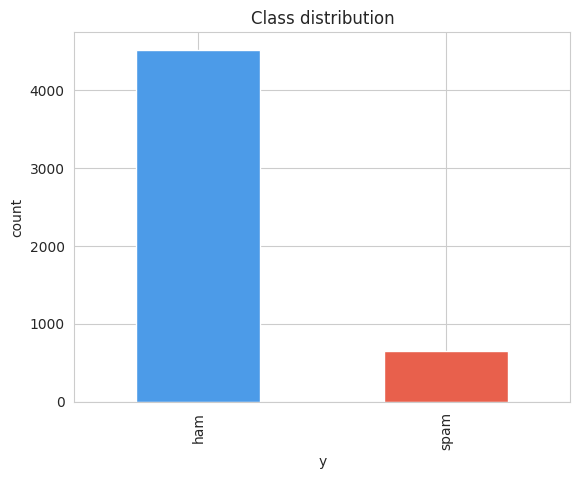

In [3]:
print(df['y'].value_counts().rename({0:'ham', 1:'spam'}))
df['y'].map({0:'ham', 1:'spam'}).value_counts().plot(kind='bar', color=['#4c9be8', '#e8604c'])
plt.title('Class distribution'); plt.ylabel('count'); plt.show()

## 4. Preprocessing + TF-IDF + split

In [4]:
def clean(t):
    t = t.lower()
    t = re.sub(r'http\S+|www\.\S+', ' url ', t)
    t = re.sub(r'\d+', ' num ', t)
    t = re.sub(r'[^a-z\s]', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

df['clean'] = df['text'].apply(clean)

X_train, X_test, y_train, y_test = train_test_split(
    df['clean'], df['y'], test_size=0.2, stratify=df['y'], random_state=42)

tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2, max_features=20000)
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)
print(Xtr.shape, Xte.shape)

(4135, 5661) (1034, 5661)


## 5. Train & evaluate all models

In [5]:
models = {
    'Naive Bayes':         MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'SVM (Linear)':        LinearSVC(class_weight='balanced'),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
}

rows, preds = [], {}
for name, m in models.items():
    t0 = time.time(); m.fit(Xtr, y_train); train_t = time.time() - t0
    t0 = time.time(); p = m.predict(Xte);  pred_t = time.time() - t0
    preds[name] = p
    rows.append({
        'Model': name,
        'Accuracy':  accuracy_score(y_test, p),
        'Precision': precision_score(y_test, p),
        'Recall':    recall_score(y_test, p),
        'F1':        f1_score(y_test, p),
        'Train time (s)': train_t,
        'Predict time (s)': pred_t,
    })

results = pd.DataFrame(rows).set_index('Model').round(4)
results.sort_values('F1', ascending=False)

,Accuracy,Precision,Recall,F1,Train time (s),Predict time (s)
Model,,,,,,
SVM (Linear),0.9836,0.9453,0.9237,0.9344,0.0368,0.0025
Random Forest,0.9816,1.0000,0.8550,0.9218,3.6062,0.1440
Logistic Regression,0.9749,0.8621,0.9542,0.9058,0.0395,0.0009
Naive Bayes,0.9768,1.0000,0.8168,0.8992,0.0064,0.0010
Decision Tree,0.9632,0.8974,0.8015,0.8468,0.2487,0.0008


## 6. Comparison charts

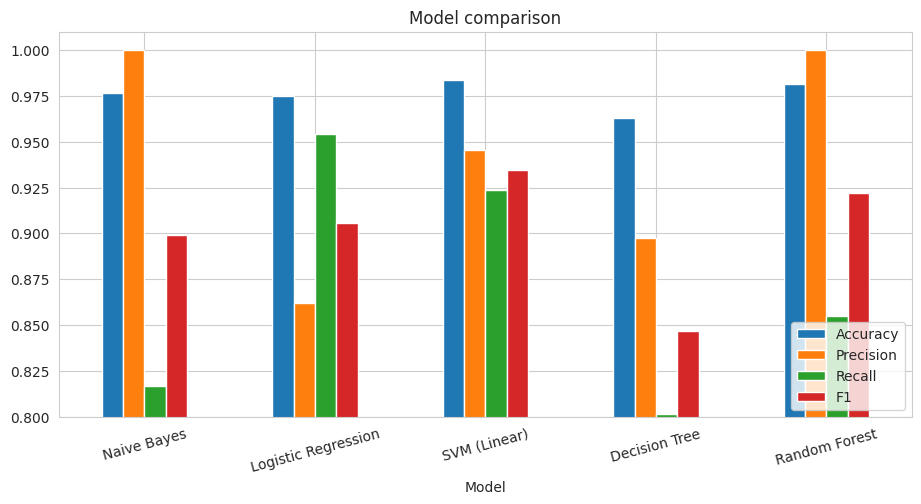

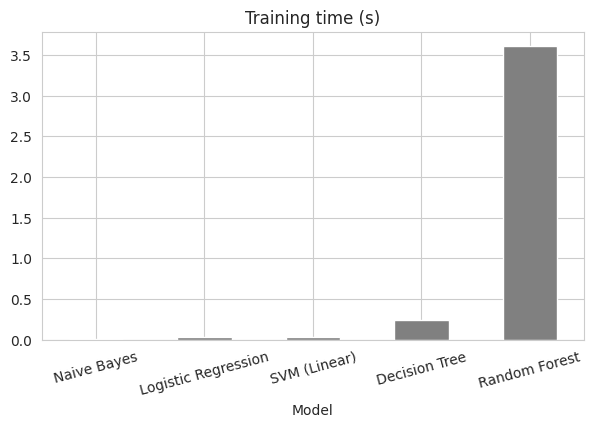

In [6]:
results[['Accuracy', 'Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(11, 5), rot=15)
plt.ylim(0.8, 1.01); plt.title('Model comparison'); plt.legend(loc='lower right'); plt.show()

results[['Train time (s)']].plot(kind='bar', figsize=(7, 4), rot=15, color='gray', legend=False)
plt.title('Training time (s)'); plt.show()

## 7. Confusion matrices

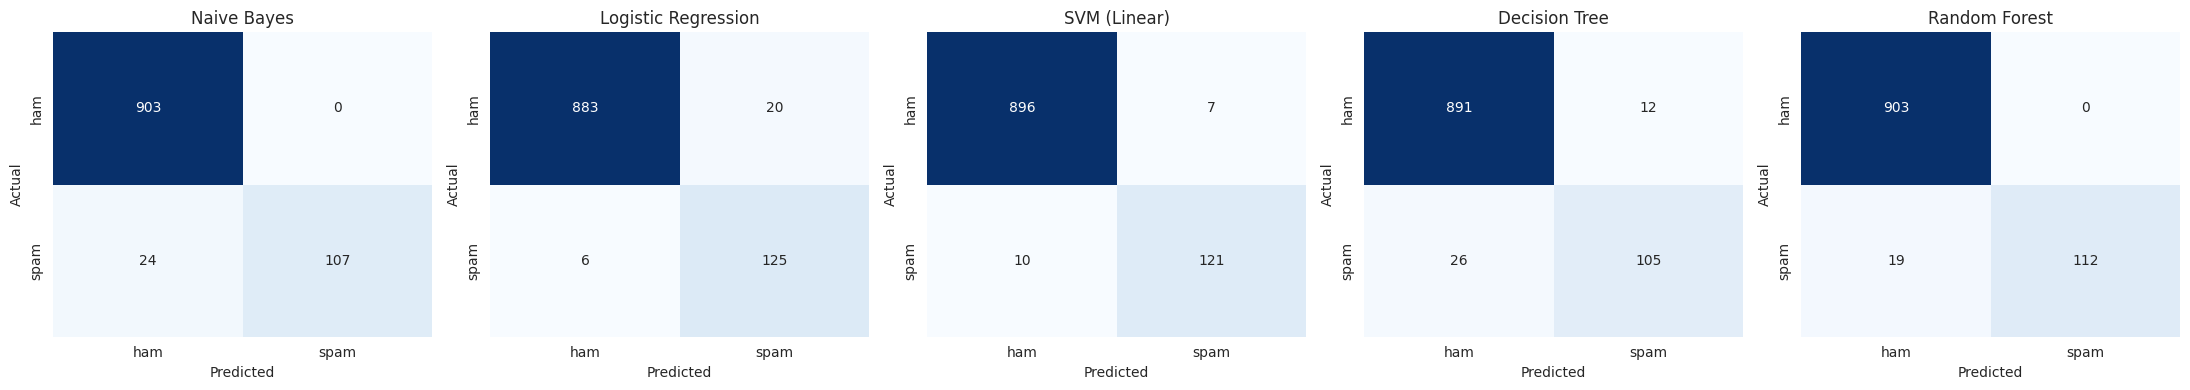

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, p) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt='d', cmap='Blues',
                xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'], ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## 8. Detailed report (best model by F1)

In [8]:
best = results['F1'].idxmax()
print('Best model:', best)
print(classification_report(y_test, preds[best], target_names=['ham', 'spam']))

Best model: SVM (Linear)
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.95      0.92      0.93       131

    accuracy                           0.98      1034
   macro avg       0.97      0.96      0.96      1034
weighted avg       0.98      0.98      0.98      1034



## 9. Test your own email

In [9]:
best_model = models[best]
def predict_email(text):
    v = tfidf.transform([clean(text)])
    return 'SPAM' if best_model.predict(v)[0] == 1 else 'HAM'

tests = [
    "Congratulations! You've won a $1000 gift card. Click http://claim-now.xyz to redeem.",
    "Hi team, the meeting is moved to 3 PM tomorrow. Please review the attached notes.",
    "URGENT: your account is suspended. Verify your password immediately.",
]
for t in tests:
    print(predict_email(t), '->', t[:70])

SPAM -> Congratulations! You've won a $1000 gift card. Click http://claim-now.
HAM -> Hi team, the meeting is moved to 3 PM tomorrow. Please review the atta
HAM -> URGENT: your account is suspended. Verify your password immediately.


## 10. Analysis notes
- **Naïve Bayes** – fastest, strong baseline for text; assumes word independence.
- **Logistic Regression / Linear SVM** – usually best on sparse TF-IDF features.
- **Decision Tree** – interpretable but tends to overfit high-dimensional text.
- **Random Forest** – more robust than a single tree, but slower and less suited to sparse text.
- For spam, **precision** matters (don't flag real mail) as much as **recall** (catch spam) – check both, not just accuracy.